In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import reti

In [2]:
df_moltbook = pd.read_pickle('df_moltbook_interactions.pkl')
df_reddit   = pd.read_pickle('df_reddit_interactions.pkl')

In [3]:
bot = ['link-navi', '[deleted]', 'AutoModerator', 'arduino-ModTeam', 'Physics-ModTeam', 'BernardJOrtcutt']
df_reddit = df_reddit[~df_reddit['mittente'].isin(bot) & ~df_reddit['destinatario'].isin(bot)]

In [4]:
rng = np.random.default_rng(0)
inizio = pd.Timestamp("2026-05-01", tz="UTC")
fine = pd.Timestamp("2026-08-01", tz="UTC")

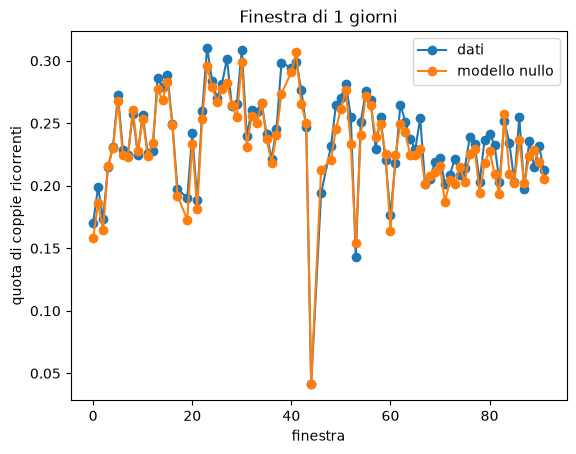

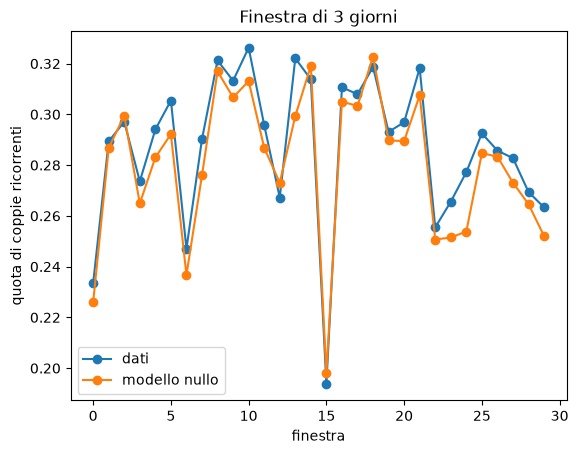

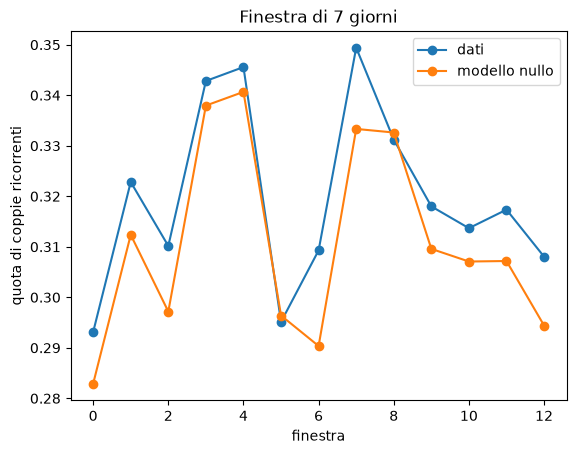

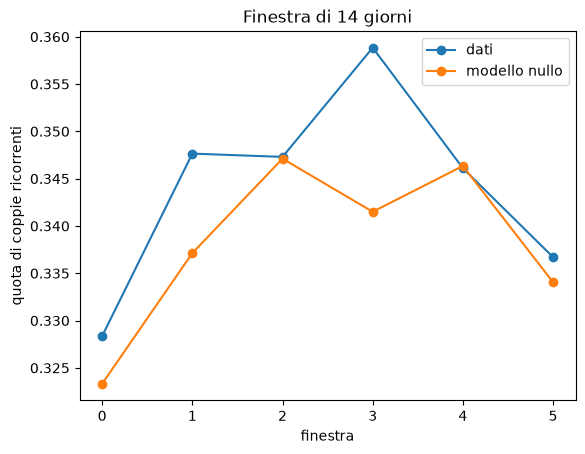

In [5]:
for w in [1, 3, 7, 14]:

    n_fin = (fine - inizio).days // w

    d = df_moltbook[(df_moltbook["t"] >= inizio) & (df_moltbook["t"] < fine)].copy()
    d["finestra"] = (d["t"] - inizio).dt.days // w
    d = d[d["finestra"] < n_fin]                         # solo finestre complete

    # 1. dati reali
    osservato = reti.quota_ricorrenti(d)

    # 2. modello nullo: destinatari rimescolati dentro ogni thread
    nulli = []
    a = d.sort_values("thread")

    b = a.assign(r=rng.random(len(a))).sort_values(["thread", "r"])
    s = a.copy()
    s["destinatario"] = b["destinatario"].values     # stessi thread, ordine casuale
    s = s[s["mittente"] != s["destinatario"]]        # niente auto-risposte
    nulli.append(reti.quota_ricorrenti(s))
    nulli = pd.concat(nulli, axis=1)                     # righe = finestre, colonne = simulazioni

    # 3. confronto
    plt.plot(osservato.index, osservato.values, marker="o", label="dati")
    plt.plot(nulli.index, nulli, marker="o", label="modello nullo")
    plt.title(f"Finestra di {w} giorni")
    plt.xlabel("finestra")
    plt.ylabel("quota di coppie ricorrenti")
    plt.legend()
    plt.show()

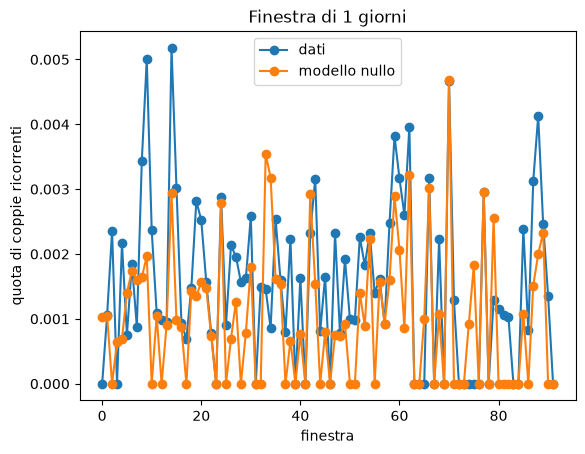

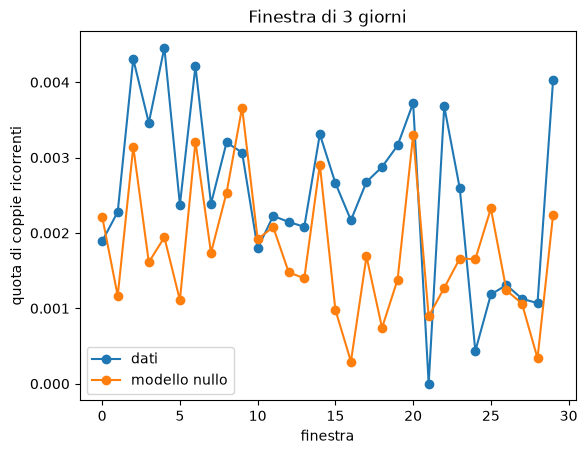

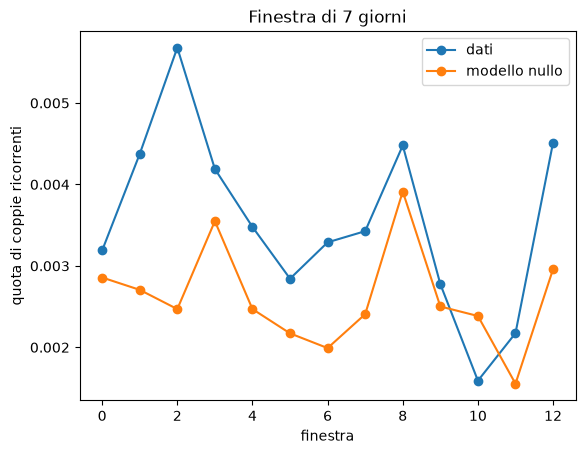

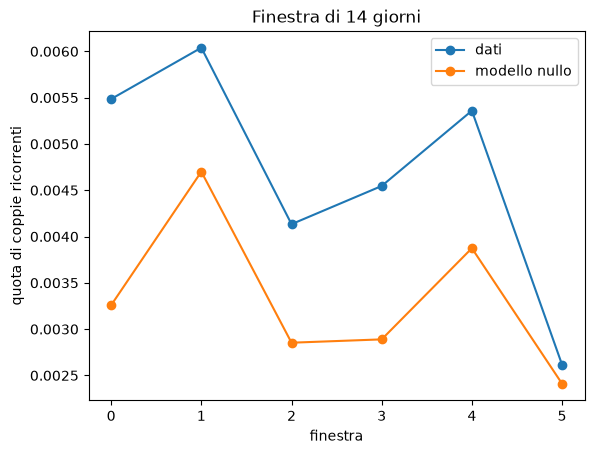

In [6]:
for w in [1, 3, 7, 14]:

    n_fin = (fine - inizio).days // w

    d = df_reddit[(df_reddit["t"] >= inizio) & (df_reddit["t"] < fine)].copy()
    d["finestra"] = (d["t"] - inizio).dt.days // w
    d = d[d["finestra"] < n_fin]                         # solo finestre complete

    # 1. dati reali
    osservato = reti.quota_ricorrenti(d)

    # 2. modello nullo: destinatari rimescolati dentro ogni thread
    nulli = []
    a = d.sort_values("thread")

    b = a.assign(r=rng.random(len(a))).sort_values(["thread", "r"])
    s = a.copy()
    s["destinatario"] = b["destinatario"].values     # stessi thread, ordine casuale
    s = s[s["mittente"] != s["destinatario"]]        # niente auto-risposte
    nulli.append(reti.quota_ricorrenti(s))
    nulli = pd.concat(nulli, axis=1)                     # righe = finestre, colonne = simulazioni

    # 3. confronto
    plt.plot(osservato.index, osservato.values, marker="o", label="dati")
    plt.plot(nulli.index, nulli, marker="o", label="modello nullo")
    plt.title(f"Finestra di {w} giorni")
    plt.xlabel("finestra")
    plt.ylabel("quota di coppie ricorrenti")
    plt.legend()
    plt.show()